# PaceForge — Component 1: Model Training

This notebook trains and evaluates the marathon finish-time model for beginner runners.
The model is **cold-start**: it needs no prior race history, so `personal_best_minutes`
is never used as an input to the main models.

**Important:** the dataset is synthetic. This notebook demonstrates the machine learning
pipeline (preprocessing, tuning, evaluation, explainability). The scores below describe
performance **on this dataset only** and are not real-world accuracy claims.

| Input | Rows |
|---|---|
| `../dataset/clean.csv` (train) | 77,577 |
| `../dataset/clean_test.csv` (test) | 19,380 |

Outputs: `../models/model.joblib`, tables in `../results/`, figures in `../figures/`.

In [1]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"  # silences the Windows loky "physical cores" warning

import sys
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             r2_score, root_mean_squared_error)
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_val_score
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

sys.path.insert(0, "..")
from src.riegel import all_distances

RANDOM_STATE = 42

os.makedirs("../models", exist_ok=True)
os.makedirs("../results", exist_ok=True)
os.makedirs("../figures", exist_ok=True)

# Chart colours (blue = ML models, grey = baselines)
BLUE = "#2a78d6"
GREY = "#898781"
INK = "#0b0b0b"
GRID = "#e1e0d9"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
})

## Step 1 — Load the data

Load the cleaned train and test files and check the row counts.

- Target `y` = `actual_finish_time_minutes`
- Features `X` (9 columns): 7 numeric and 2 categorical.
- `personal_best_minutes` is **never** in `X` for the main models. It is only used for
  the Riegel baseline (Step 5) and the PB ablation (Step 6).

In [2]:
train = pd.read_csv("../dataset/clean.csv")
test = pd.read_csv("../dataset/clean_test.csv")

assert len(train) == 77_577
assert len(test) == 19_380

TARGET = "actual_finish_time_minutes"
NUMERIC = [
    "age",
    "bmi",
    "weekly_km",
    "runs_per_week",
    "long_run_distance_km",
    "resting_heart_rate_bpm",
    "running_experience_months",
]
CATEGORICAL = ["gender", "course_difficulty"]
FEATURES = NUMERIC + CATEGORICAL

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (77577, 9) | Test: (19380, 9)


## Step 2 — Train / test setup

There is **no** `train_test_split`. The dataset comes with its own independent test set:

- **Train** = all of `clean.csv`. Used for fitting and for 5-fold cross-validation (CV)
  during tuning.
- **Test** = all of `clean_test.csv`. Used **only** for the final scores. It is never
  used for tuning.

In [3]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("Training rows:", len(X_train), "| Test rows (final scores only):", len(X_test))

Training rows: 77577 | Test rows (final scores only): 19380


## Step 3 — Preprocessing (inside the Pipeline)

One `ColumnTransformer` handles all preprocessing:

| Columns | Transformer |
|---|---|
| 7 numeric columns | `StandardScaler` |
| `gender` | `OneHotEncoder(drop="first")` (Female is the reference; Male and Non-binary each get a column) |
| `course_difficulty` | `OrdinalEncoder`: Flat = 0, Mixed = 1, Hilly = 2 |

Every model is wrapped as `Pipeline([("pre", preprocessor), ("model", model)])`. During
cross-validation, the scaler and encoders are fit on the training folds only, so no
information from the validation fold (or the test set) leaks into preprocessing.

`build_pipeline` creates a fresh preprocessor each time. It takes the list of numeric
columns as an argument so the ablations in Step 6 can add or remove one column.

In [4]:
def build_pipeline(model, numeric_cols=NUMERIC):
    preprocessor = ColumnTransformer([
        ("num", StandardScaler(), numeric_cols),
        ("gender", OneHotEncoder(drop="first"), ["gender"]),
        ("course", OrdinalEncoder(categories=[["Flat", "Mixed", "Hilly"]]), ["course_difficulty"]),
    ])
    return Pipeline([("pre", preprocessor), ("model", model)])


build_pipeline(LinearRegression())

Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi', 'weekly_km',
                                                   'runs_per_week',
                                                   'long_run_distance_km',
                                                   'resting_heart_rate_bpm',
                                                   'running_experience_months']),
                                                 ('gender',
                                                  OneHotEncoder(drop='first'),
                                                  ['gender']),
                                                 ('course',
                                                  OrdinalEncoder(categories=[['Flat',
                                                                              'Mixed',
                                                                              'Hilly']]),
                                                  ['course_difficulty'])])),
                ('model', LinearRegression())])

## Step 4 — Train and tune the 4 models

Linear regression is the baseline and has no hyperparameters to tune. The other three
models are tuned with `RandomizedSearchCV` on the **train set only**: 5-fold CV,
scoring = negative MAE, `random_state=42`, `n_jobs=-1`.

| Model | Class | n_iter | Search space |
|---|---|---|---|
| Linear regression (baseline) | `LinearRegression` | no tuning | – |
| Random forest | `RandomForestRegressor` | 10 | n_estimators [100, 200]; max_depth [None, 10, 20]; min_samples_leaf [1, 5, 10]; max_features ["sqrt", 0.5, 1.0] |
| Gradient boosting | `HistGradientBoostingRegressor` | 20 | learning_rate [0.03, 0.05, 0.1]; max_iter [200, 400, 800]; max_depth [None, 4, 8]; min_samples_leaf [20, 50, 100]; l2_regularization [0, 0.1, 1.0] |
| Neural network | `MLPRegressor(early_stopping=True, max_iter=500)` | 20 | hidden_layer_sizes [(32,), (64, 32), (128, 64)]; alpha [1e-4, 1e-3, 1e-2]; learning_rate_init [1e-3, 1e-2] |

Note: the neural network search space has only 3 × 3 × 2 = 18 combinations, fewer than
`n_iter=20`. scikit-learn then tries all 18 (it cannot sample more combinations than
exist), so for this model the search is effectively a full grid search.

After the search, `RandomizedSearchCV` refits the best settings on the full train set.
The best settings and their CV MAE are saved to `results/best_params.csv`.

In [5]:
SEARCHES = {
    "Random forest": (
        RandomForestRegressor(random_state=RANDOM_STATE),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [None, 10, 20],
            "model__min_samples_leaf": [1, 5, 10],
            "model__max_features": ["sqrt", 0.5, 1.0],
        },
        10,
    ),
    "Gradient boosting": (
        HistGradientBoostingRegressor(random_state=RANDOM_STATE),
        {
            "model__learning_rate": [0.03, 0.05, 0.1],
            "model__max_iter": [200, 400, 800],
            "model__max_depth": [None, 4, 8],
            "model__min_samples_leaf": [20, 50, 100],
            "model__l2_regularization": [0, 0.1, 1.0],
        },
        20,
    ),
    "Neural network": (
        MLPRegressor(early_stopping=True, max_iter=500, random_state=RANDOM_STATE),
        {
            "model__hidden_layer_sizes": [(32,), (64, 32), (128, 64)],
            "model__alpha": [1e-4, 1e-3, 1e-2],
            "model__learning_rate_init": [1e-3, 1e-2],
        },
        20,
    ),
}

tuned = {}
param_rows = []

# Linear regression: no tuning, but report its CV MAE for comparison
lr_pipeline = build_pipeline(LinearRegression())
lr_cv_mae = -cross_val_score(lr_pipeline, X_train, y_train, cv=cv,
                             scoring="neg_mean_absolute_error", n_jobs=-1).mean()
tuned["Linear regression"] = lr_pipeline.fit(X_train, y_train)
param_rows.append({"Model": "Linear regression", "Best params": "no tuning",
                   "CV MAE": round(lr_cv_mae, 2)})
print(f"Linear regression: CV MAE = {lr_cv_mae:.2f}")

for name, (model, space, n_iter) in SEARCHES.items():
    start = time.time()
    search = RandomizedSearchCV(
        build_pipeline(model),
        space,
        n_iter=n_iter,
        cv=cv,
        scoring="neg_mean_absolute_error",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    search.fit(X_train, y_train)
    tuned[name] = search.best_estimator_

    best = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    param_rows.append({"Model": name, "Best params": str(best),
                       "CV MAE": round(-search.best_score_, 2)})
    print(f"{name}: CV MAE = {-search.best_score_:.2f} | {best} "
          f"| {time.time() - start:.0f} s")

best_params = pd.DataFrame(param_rows)
best_params.to_csv("../results/best_params.csv", index=False)
best_params

Linear regression: CV MAE = 19.57
Random forest: CV MAE = 17.31 | {'n_estimators': 100, 'min_samples_leaf': 5, 'max_features': 1.0, 'max_depth': 10} | 310 s
Gradient boosting: CV MAE = 17.27 | {'min_samples_leaf': 20, 'max_iter': 800, 'max_depth': 4, 'learning_rate': 0.03, 'l2_regularization': 0} | 39 s


c:\Users\Ahmad Naji\anaconda3\Lib\site-packages\sklearn\model_selection\_search.py:320: UserWarning: The total space of parameters 18 is smaller than n_iter=20. Running 18 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Neural network: CV MAE = 18.05 | {'learning_rate_init': 0.001, 'hidden_layer_sizes': (128, 64), 'alpha': 0.0001} | 378 s


,Model,Best params,CV MAE
0,Linear regression,no tuning,19.57
1,Random forest,"{'n_estimators': 100, 'min_samples_leaf': 5, '...",17.31
2,Gradient boosting,"{'min_samples_leaf': 20, 'max_iter': 800, 'max...",17.27
3,Neural network,"{'learning_rate_init': 0.001, 'hidden_layer_si...",18.05


## Step 5 — Evaluate on the test set

`evaluate` returns four metrics. MAE and RMSE are in minutes, MAPE is in %, and R² has
no unit.

**Table 1** scores all 4 tuned models on the full test set, plus a mean predictor
(`DummyRegressor`, which always predicts the training-set mean finish time). Any useful
model must beat the mean predictor.

**Table 2** splits the test set into two groups:

- **Has PB:** runners with a previous marathon time. Here we also score the **Riegel
  baseline**. Riegel's formula converts a time at one distance into a time at another.
  From marathon to marathon the distance ratio is 1, so the Riegel prediction is simply
  the runner's personal best.
- **First-timer:** runners with no previous marathon. Riegel cannot be applied
  ("N/A (no prior race)"). This is the cold-start case PaceForge is built for.

The best model is the one with the lowest MAE on the full test set.

In [6]:
def evaluate(y_true, y_pred):
    return {
        "MAE": round(mean_absolute_error(y_true, y_pred), 1),
        "RMSE": round(root_mean_squared_error(y_true, y_pred), 1),
        "MAPE (%)": round(mean_absolute_percentage_error(y_true, y_pred) * 100, 1),
        "R2": round(r2_score(y_true, y_pred), 3),
    }


# Table 1: full test set
mean_predictor = DummyRegressor(strategy="mean").fit(X_train, y_train)

rows = []
for name, pipeline in tuned.items():
    rows.append({"Model": name, **evaluate(y_test, pipeline.predict(X_test))})
rows.append({"Model": "Mean predictor", **evaluate(y_test, mean_predictor.predict(X_test))})

table1 = pd.DataFrame(rows)
table1.to_csv("../results/table1_test_overall.csv", index=False)
table1

,Model,MAE,RMSE,MAPE (%),R2
0,Linear regression,19.5,24.6,7.0,0.465
1,Random forest,17.3,21.7,6.1,0.583
2,Gradient boosting,17.3,21.7,6.1,0.585
3,Neural network,18.2,22.8,6.4,0.541
4,Mean predictor,27.4,33.7,9.9,-0.000


In [7]:
# Table 2: by group within the test set
has_pb = test["personal_best_minutes"].notna()
groups = {"Has PB": has_pb, "First-timer": ~has_pb}
print("Has PB:", has_pb.sum(), "runners | First-timer:", (~has_pb).sum(), "runners")
assert has_pb.sum() == 16_809
assert (~has_pb).sum() == 2_571

rows = []
for group, mask in groups.items():
    for name, pipeline in tuned.items():
        y_pred = pipeline.predict(X_test[mask])
        rows.append({"Group": group, "n": mask.sum(), "Model": name,
                     **evaluate(y_test[mask], y_pred)})

    if group == "Has PB":
        riegel_pred = test.loc[mask, "personal_best_minutes"]
        rows.append({"Group": group, "n": mask.sum(), "Model": "Riegel baseline",
                     **evaluate(y_test[mask], riegel_pred)})
    else:
        rows.append({"Group": group, "n": mask.sum(), "Model": "Riegel baseline",
                     "MAE": "N/A (no prior race)", "RMSE": "N/A", "MAPE (%)": "N/A", "R2": "N/A"})

table2 = pd.DataFrame(rows)
table2.to_csv("../results/table2_test_by_group.csv", index=False)
table2

Has PB: 16809 runners | First-timer: 2571 runners


,Group,n,Model,MAE,RMSE,MAPE (%),R2
0,Has PB,16809,Linear regression,19.5,24.6,7.0,0.464
1,Has PB,16809,Random forest,17.3,21.7,6.1,0.582
2,Has PB,16809,Gradient boosting,17.3,21.7,6.1,0.584
3,Has PB,16809,Neural network,18.2,22.8,6.4,0.54
4,Has PB,16809,Riegel baseline,29.6,33.9,10.2,-0.019
5,First-timer,2571,Linear regression,19.5,24.8,7.0,0.473
6,First-timer,2571,Random forest,17.4,21.9,6.2,0.591
7,First-timer,2571,Gradient boosting,17.3,21.8,6.1,0.592
8,First-timer,2571,Neural network,18.2,22.9,6.4,0.552
9,First-timer,2571,Riegel baseline,N/A (no prior race),N/A,N/A,N/A


**Reading the Riegel result.** On this dataset the ML models have a lower MAE than the
Riegel baseline in the has-PB group. This is a result **on this dataset only**, and the
synthetic data puts Riegel at a disadvantage: most runners finished **slower** than their
personal best (computed below). A baseline that predicts "you will run your PB" is
therefore biased towards times that are too fast.

In [8]:
slower = test[TARGET] > test["personal_best_minutes"]  # False when there is no PB

pct_of_has_pb = slower[has_pb].mean() * 100
pct_of_all = slower.mean() * 100
print(f"Finished slower than their PB: {pct_of_has_pb:.1f}% of has-PB runners "
      f"({pct_of_all:.1f}% of all test runners)")

Finished slower than their PB: 94.2% of has-PB runners (81.7% of all test runners)


In [9]:
# Compare UNROUNDED test MAE, because two models can tie after rounding to 1 decimal
test_mae = {name: mean_absolute_error(y_test, pipeline.predict(X_test))
            for name, pipeline in tuned.items()}
for name, mae in test_mae.items():
    print(f"{name}: test MAE = {mae:.3f}")

best_name = min(test_mae, key=test_mae.get)
best_pipeline = tuned[best_name]
print("Best model (lowest test MAE):", best_name)

Linear regression: test MAE = 19.504
Random forest: test MAE = 17.340
Gradient boosting: test MAE = 17.287
Neural network: test MAE = 18.187
Best model (lowest test MAE): Gradient boosting


## Step 6 — Ablations

Each ablation changes one thing, trains on the full train set and is scored on the test
set with the Step 5 metrics. Both use the tuned settings from Step 4.

- **A: + `personal_best_minutes`.** Adds the PB as a 10th feature. This shows how much
  accuracy PaceForge gives up by being cold-start. First-timers have no PB (NaN), so this
  ablation always uses **HistGradientBoosting**, which handles NaN natively. If the best
  model is a different type, the output below says so.
- **B: − `running_experience_months`.** Removes one feature from the best model, to show
  how much the model depends on it.

The first row repeats the best model's Step 5 result as the reference.

In [10]:
rows = [{"Ablation": f"Reference: {best_name}, 9 features",
         **evaluate(y_test, best_pipeline.predict(X_test))}]

# A: + personal_best_minutes (always HistGradientBoosting, with its tuned settings)
if best_name != "Gradient boosting":
    print(f"Note: the best model is {best_name}, but ablation A uses HistGradientBoosting "
          "because it handles the NaN personal bests natively.")
hgb = clone(tuned["Gradient boosting"].named_steps["model"])
numeric_a = NUMERIC + ["personal_best_minutes"]
features_a = numeric_a + CATEGORICAL
pipeline_a = build_pipeline(hgb, numeric_a).fit(train[features_a], y_train)
rows.append({"Ablation": "A: Gradient boosting + personal_best_minutes",
             **evaluate(y_test, pipeline_a.predict(test[features_a]))})

# B: - running_experience_months (best model type, with its tuned settings)
best_model = clone(best_pipeline.named_steps["model"])
numeric_b = [c for c in NUMERIC if c != "running_experience_months"]
features_b = numeric_b + CATEGORICAL
pipeline_b = build_pipeline(best_model, numeric_b).fit(train[features_b], y_train)
rows.append({"Ablation": f"B: {best_name} - running_experience_months",
             **evaluate(y_test, pipeline_b.predict(test[features_b]))})

ablations = pd.DataFrame(rows)
ablations.to_csv("../results/ablations.csv", index=False)
ablations

,Ablation,MAE,RMSE,MAPE (%),R2
0,"Reference: Gradient boosting, 9 features",17.3,21.7,6.1,0.585
1,A: Gradient boosting + personal_best_minutes,12.3,15.7,4.3,0.783
2,B: Gradient boosting - running_experience_months,24.4,30.5,8.7,0.181


## Step 7 — Explainability and plots

**Permutation importance** shuffles one feature at a time in the test set and measures
how much the MAE gets worse. A big increase means the model relies on that feature. The
whole pipeline is passed in, so importance is measured on the **9 original columns**
(e.g. `gender` as one feature, not its one-hot columns). Settings: `n_repeats=10`,
`scoring="neg_mean_absolute_error"`, `random_state=42`.

Then the plots: actual vs predicted (plus a diagnostic version coloured by training
program), residual histogram, and MAE of all models and both baselines. All figures are
saved as 300 dpi PNGs in `../figures/`.

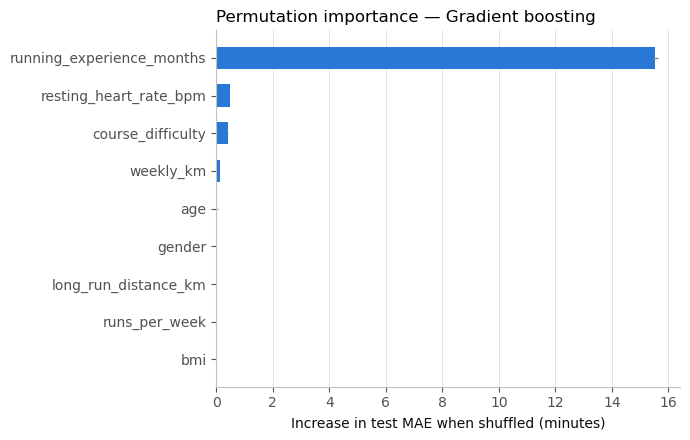

,Feature,MAE increase (min),Std
6,running_experience_months,15.54,0.09
5,resting_heart_rate_bpm,0.49,0.01
8,course_difficulty,0.41,0.02
2,weekly_km,0.13,0.01
0,age,0.04,0.01
1,bmi,0.00,0.00
3,runs_per_week,0.00,0.00
4,long_run_distance_km,0.00,0.00
7,gender,0.00,0.00


In [11]:
perm = permutation_importance(
    best_pipeline, X_test, y_test,
    n_repeats=10,
    scoring="neg_mean_absolute_error",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
importance = pd.DataFrame({
    "Feature": FEATURES,
    "MAE increase (min)": perm.importances_mean.round(2),
    "Std": perm.importances_std.round(2),
}).sort_values("MAE increase (min)", ascending=False)
importance.to_csv("../results/permutation_importance.csv", index=False)

ordered = importance.sort_values("MAE increase (min)")
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(ordered["Feature"], ordered["MAE increase (min)"], xerr=ordered["Std"],
        color=BLUE, height=0.6, error_kw={"ecolor": GREY, "lw": 1})
ax.set_xlabel("Increase in test MAE when shuffled (minutes)")
ax.set_title(f"Permutation importance — {best_name}", loc="left")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig("../figures/permutation_importance.png", dpi=300)
plt.show()
importance

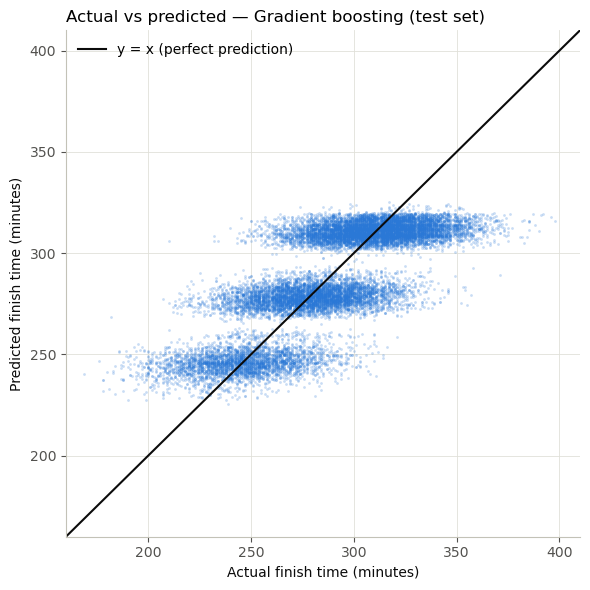

In [12]:
y_pred_best = best_pipeline.predict(X_test)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, y_pred_best, s=4, alpha=0.25, color=BLUE, linewidths=0)
low, high = 160, 410
ax.plot([low, high], [low, high], color=INK, lw=1.5, label="y = x (perfect prediction)")
ax.set_xlim(low, high)
ax.set_ylim(low, high)
ax.set_xlabel("Actual finish time (minutes)")
ax.set_ylabel("Predicted finish time (minutes)")
ax.set_title(f"Actual vs predicted — {best_name} (test set)", loc="left")
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig("../figures/actual_vs_predicted.png", dpi=300)
plt.show()

### Diagnostic — why the predictions form 3 bands

The actual-vs-predicted plot shows the predictions in **3 horizontal bands**. The raw data
has a `training_program` column (Beginner / Intermediate / Advanced) that was dropped
during cleaning. In this synthetic data, running experience maps **one-to-one** onto the
3 program tiers:

| Program | Running experience |
|---|---|
| Beginner | 6–24 months |
| Intermediate | 25–60 months |
| Advanced | 61–240 months |

Each tier has its own average finish time, so once the model knows a runner's experience
it effectively knows their tier, and it predicts close to that tier's average. This is
also why `running_experience_months` dominates the permutation importance.

This is a **dataset limitation, not leakage**. Running experience is a legitimate input
that a runner knows before the race, and `training_program` is **not** a model feature.
It is merged in below only to explain the plot.

In [13]:
raw_test = pd.read_csv("../dataset/test.csv", usecols=["runner_id", "training_program"])

diagnostic = test[["runner_id", "running_experience_months", TARGET]].copy()
diagnostic["predicted"] = y_pred_best
diagnostic = diagnostic.merge(raw_test, on="runner_id", how="left")
assert diagnostic["training_program"].notna().all()

PROGRAMS = ["Beginner", "Intermediate", "Advanced"]
program_table = diagnostic.groupby("training_program").agg(
    Runners=("runner_id", "size"),
    Min_experience_months=("running_experience_months", "min"),
    Max_experience_months=("running_experience_months", "max"),
    Mean_actual_finish_min=(TARGET, "mean"),
).reindex(PROGRAMS).round(1)

program_table.to_csv("../results/program_diagnostic.csv")
program_table

,Runners,Min_experience_months,Max_experience_months,Mean_actual_finish_min
training_program,,,,
Beginner,9650,6,24,310.7
Intermediate,6113,25,60,278.3
Advanced,3617,61,240,244.9


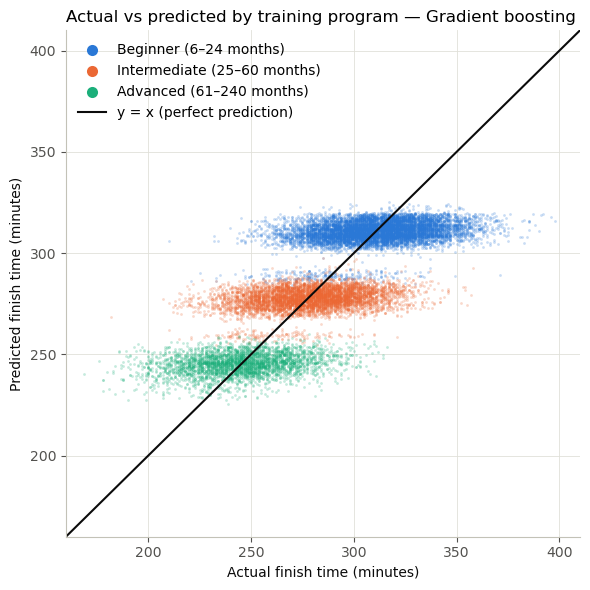

In [14]:
# Categorical colours, one fixed colour per program
PROGRAM_COLORS = {"Beginner": "#2a78d6", "Intermediate": "#eb6834", "Advanced": "#1baf7a"}

fig, ax = plt.subplots(figsize=(6, 6))
for program in PROGRAMS:
    rows = diagnostic[diagnostic["training_program"] == program]
    label = (f"{program} ({rows['running_experience_months'].min()}–"
             f"{rows['running_experience_months'].max()} months)")
    ax.scatter(rows[TARGET], rows["predicted"], s=4, alpha=0.25,
               color=PROGRAM_COLORS[program], linewidths=0, label=label)

low, high = 160, 410
ax.plot([low, high], [low, high], color=INK, lw=1.5, label="y = x (perfect prediction)")
ax.set_xlim(low, high)
ax.set_ylim(low, high)
ax.set_xlabel("Actual finish time (minutes)")
ax.set_ylabel("Predicted finish time (minutes)")
ax.set_title(f"Actual vs predicted by training program — {best_name}", loc="left")
legend = ax.legend(loc="upper left", frameon=False, markerscale=4)
for handle in legend.legend_handles:
    handle.set_alpha(1)
fig.tight_layout()
fig.savefig("../figures/actual_vs_predicted_by_program.png", dpi=300)
plt.show()

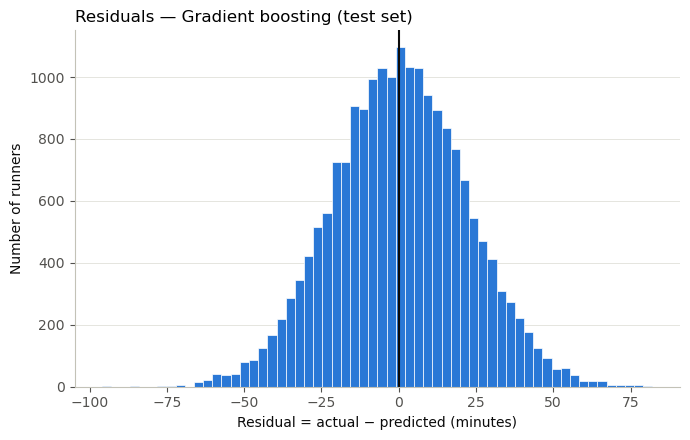

Mean residual: 0.3 min | Std: 21.7 min


In [15]:
residuals = y_test - y_pred_best  # positive = runner was slower than predicted

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(residuals, bins=60, color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(0, color=INK, lw=1.5)
ax.set_xlabel("Residual = actual − predicted (minutes)")
ax.set_ylabel("Number of runners")
ax.set_title(f"Residuals — {best_name} (test set)", loc="left")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig("../figures/residual_histogram.png", dpi=300)
plt.show()

print(f"Mean residual: {residuals.mean():.1f} min | Std: {residuals.std():.1f} min")

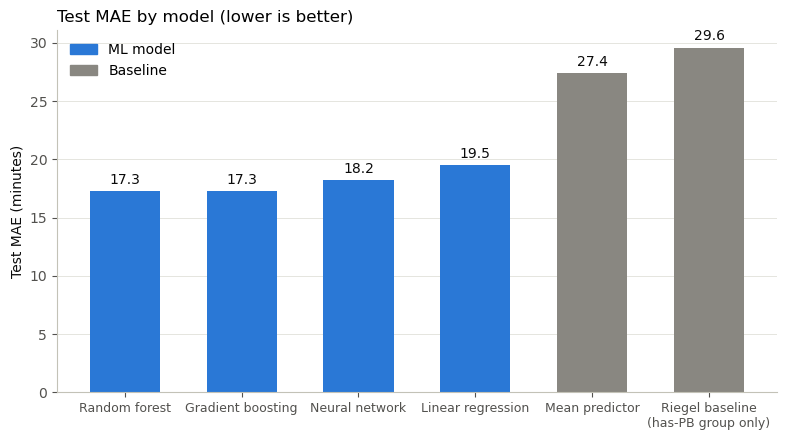

In [16]:
riegel_mae = table2.loc[(table2["Group"] == "Has PB") & (table2["Model"] == "Riegel baseline"), "MAE"].iloc[0]

mae_chart = pd.DataFrame({
    "Model": list(table1["Model"]) + ["Riegel baseline\n(has-PB group only)"],
    "MAE": list(table1["MAE"]) + [riegel_mae],
})
mae_chart["Is baseline"] = mae_chart["Model"].str.startswith(("Mean", "Riegel"))
mae_chart = mae_chart.sort_values("MAE")

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = [GREY if b else BLUE for b in mae_chart["Is baseline"]]
bars = ax.bar(mae_chart["Model"], mae_chart["MAE"], color=colors, width=0.6)
ax.bar_label(bars, fmt="%.1f", padding=3, color=INK)
ax.set_ylabel("Test MAE (minutes)")
ax.set_title("Test MAE by model (lower is better)", loc="left")
ax.grid(axis="x", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=GREY)],
          labels=["ML model", "Baseline"], frameon=False, loc="upper left")
plt.setp(ax.get_xticklabels(), fontsize=9)
fig.tight_layout()
fig.savefig("../figures/mae_comparison.png", dpi=300)
plt.show()

Note: the Riegel bar is scored on the has-PB group only (16,809 runners), because
Riegel cannot be applied to first-timers. All other bars are scored on the full test
set (19,380 runners).

## Step 8 — Save the best model

The whole pipeline (preprocessing + model) is saved, so the app can pass raw inputs
straight in. To check the file works, we reload it and confirm it gives the same
prediction for one test row.

In [17]:
joblib.dump(best_pipeline, "../models/model.joblib")

reloaded = joblib.load("../models/model.joblib")
one_row = X_test.iloc[[0]]
original = best_pipeline.predict(one_row)[0]
after_reload = reloaded.predict(one_row)[0]

print(f"Saved {best_name}. Prediction before: {original:.2f} min | after reload: {after_reload:.2f} min")
assert original == after_reload

Saved Gradient boosting. Prediction before: 279.84 min | after reload: 279.84 min


## Step 9 — Riegel conversion to other distances

The model predicts a marathon time. `src/riegel.py` converts it to 5K, 10K and 21K
times with Riegel's formula, T2 = T1 × (D2 / D1)^1.06. Demo on 3 test-set predictions.

In [18]:
def to_hms(minutes):
    total_seconds = round(minutes * 60)
    hours, rest = divmod(total_seconds, 3600)
    mins, secs = divmod(rest, 60)
    return f"{hours}:{mins:02d}:{secs:02d}"


rows = []
for i in range(3):
    predicted = y_pred_best[i]
    times = all_distances(predicted)
    rows.append({"runner_id": test["runner_id"].iloc[i],
                 **{distance: to_hms(t) for distance, t in times.items()}})

riegel_demo = pd.DataFrame(rows)
riegel_demo.to_csv("../results/riegel_demo.csv", index=False)
riegel_demo

,runner_id,5K,10K,21K,42K
0,R043064,0:29:11,1:00:50,2:14:13,4:39:50
1,R030159,0:32:58,1:08:44,2:31:39,5:16:11
2,R033974,0:32:39,1:08:05,2:30:13,5:13:12
